In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

df = pd.read_csv("cars.csv")

df.head()

,brand,km_driven,fuel,owner,selling_price
0,Maruti,145500,Diesel,First Owner,450000
1,Skoda,120000,Diesel,Second Owner,370000
2,Honda,140000,Petrol,Third Owner,158000
3,Hyundai,127000,Diesel,First Owner,225000
4,Maruti,120000,Petrol,First Owner,130000


In [2]:
X = df.drop(columns=['selling_price'])
Y = df['selling_price']

In [3]:
x_train, x_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

In [4]:
d = x_train.select_dtypes(include=['object']).columns

print(d)

Index(['brand', 'fuel', 'owner'], dtype='str')


C:\Users\kanheya\AppData\Local\Temp\ipykernel_8832\3159368457.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  d = x_train.select_dtypes(include=['object']).columns


In [5]:
ohe = OneHotEncoder(
    sparse_output=False,
    dtype=np.int32,
    handle_unknown='ignore'
)

encoded_value = ohe.fit_transform(x_train[d])

encoded_test = ohe.transform(x_test[d])

In [6]:
e_column = ohe.get_feature_names_out(d)

print(e_column)

['brand_Ambassador' 'brand_Ashok' 'brand_Audi' 'brand_BMW'
 'brand_Chevrolet' 'brand_Daewoo' 'brand_Datsun' 'brand_Fiat'
 'brand_Force' 'brand_Ford' 'brand_Honda' 'brand_Hyundai' 'brand_Isuzu'
 'brand_Jaguar' 'brand_Jeep' 'brand_Kia' 'brand_Land' 'brand_Lexus'
 'brand_MG' 'brand_Mahindra' 'brand_Maruti' 'brand_Mercedes-Benz'
 'brand_Mitsubishi' 'brand_Nissan' 'brand_Opel' 'brand_Peugeot'
 'brand_Renault' 'brand_Skoda' 'brand_Tata' 'brand_Toyota'
 'brand_Volkswagen' 'brand_Volvo' 'fuel_CNG' 'fuel_Diesel' 'fuel_LPG'
 'fuel_Petrol' 'owner_First Owner' 'owner_Fourth & Above Owner'
 'owner_Second Owner' 'owner_Test Drive Car' 'owner_Third Owner']


In [7]:
x_train_num = x_train.drop(columns=d).to_numpy()
x_test_num = x_test.drop(columns=d).to_numpy()

xtrain = np.hstack((x_train_num, encoded_value))
xtest = np.hstack((x_test_num, encoded_test))

In [8]:
model = LinearRegression()

model.fit(xtrain, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [9]:
y_predicted = model.predict(xtest)

In [10]:
print("R2 Score:", r2_score(y_test, y_predicted))

print("Mean Absolute Error:", mean_absolute_error(y_test, y_predicted))

R2 Score: 0.7778397792229395
Mean Absolute Error: 216466.22623961983


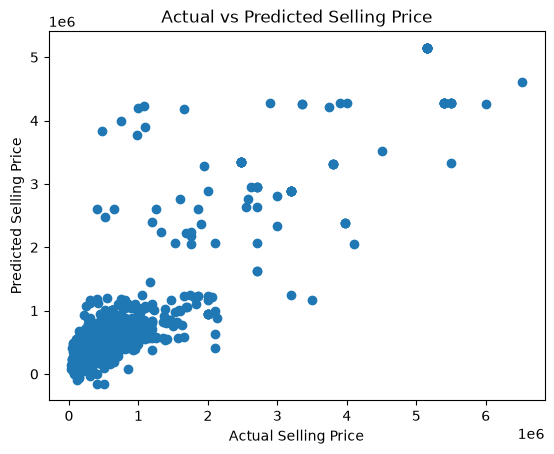

In [11]:
plt.scatter(y_test, y_predicted)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Selling Price")

plt.show()

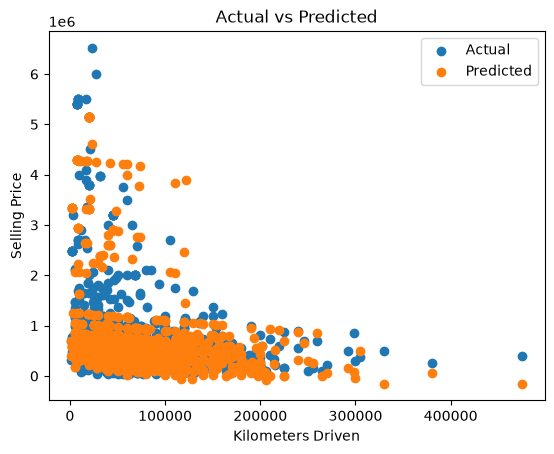

In [14]:
plt.scatter(x_test['km_driven'], y_test, label='Actual')

plt.scatter(x_test['km_driven'], y_predicted, label='Predicted')

plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price")

plt.title("Actual vs Predicted")
plt.legend()

plt.show()